# Data files from the STAC API

`WaterDataSTAC` queries the USGS Water Data STAC API, which lists data files: each item
describes one file, and its `assets` link to that file. It sends the key in
`USGS_STAC_API_KEY`, or in `USGS_API_KEY` when that is unset. This notebook lists the
collections, finds every file of the Potomac River gage, maps the sites of a basin,
then downloads the gage's daily values and plots its discharge. `to_arrow()` turns a
result into a table for geopandas, which needs the `arrow` extra.

In [1]:
from water_ogcapi import WaterDataSTAC

SITE = "USGS-01646500"
stac = WaterDataSTAC()

A service keeps its HTTP connections open until it is closed. In a script, use it in
a `with` block, `with WaterDataSTAC() as stac:`, which closes it on exit. A notebook
keeps one service across cells, so it calls `stac.close()` explicitly in its last cell.

## Look at the collections

Each collection is one kind of file. `queryables()` lists the properties a query can
name; the items carry site metadata, not the parameters or periods inside the files.

In [2]:
for collection in stac.collections().collections or ():
    print(f"{collection.id:12} {collection.title}")

continuous   Continuous time series data
daily        Daily values time series data
ratings      USGS Stage Discharge Rating Curves


In [3]:
print(", ".join(stac.queryables("daily").properties or {}))

id, altitude, datetime, geometry, site_type, basin_code, state_code, state_name, agency_code, agency_name, county_code, county_name, aquifer_code, country_code, country_name, end_datetime, district_code, drainage_area, revision_note, site_type_code, start_datetime, vertical_datum, revision_created, altitude_accuracy, aquifer_type_code, construction_date, depth_source_code, revision_modified, vertical_datum_name, altitude_method_code, altitude_method_name, hydrologic_unit_code, national_aquifer_code, uses_daylight_savings, hole_constructed_depth, monitoring_location_id, time_zone_abbreviation, well_constructed_depth, monitoring_location_name, minor_civil_division_code, original_horizontal_datum, contributing_drainage_area, monitoring_location_number, horizontal_positional_accuracy, original_horizontal_datum_name, horizontal_position_method_code, horizontal_position_method_name, horizontal_positional_accuracy_code


## Find one gage's files

`ids` with `id_property` matches items by site. A site list longer than 50 runs as
concurrent pieces, since the service refuses a long query URL. Each item's `assets`
name its files: `continuous` splits the last 150 days, `current`, from the older
`historical` values.

In [4]:
for collection in ("continuous", "daily", "ratings"):
    result = stac.collect(collection, ids=[SITE], id_property="monitoring_location_id")
    for item in result.geojson["features"]:
        print(f"{collection:11} {item['id']:24} {', '.join(item['assets'])}")

continuous  USGS-01646500            current, historical


daily       USGS-01646500            data


ratings     USGS-01646500.exsa.rdb   data
ratings     USGS-01646500.corr.rdb   data
ratings     USGS-01646500.base.rdb   data


## Map the sites of a basin

The items carry each site's hydrologic unit code, so a CQL2-Text `LIKE` selects a
basin by its prefix: here `02070008`, the Middle Potomac-Catoctin.

In [5]:
import geopandas as gpd

basin = stac.collect("daily", filter="hydrologic_unit_code LIKE '02070008%'")
sites = gpd.GeoDataFrame.from_arrow(basin.to_arrow())
print(len(sites), "sites with daily values,", basin.pagination.completeness)
sites[["id", "monitoring_location_name", "site_type", "drainage_area"]].head()

50 sites with daily values, complete


,id,monitoring_location_name,site_type,drainage_area
0,USGS-01636765,POTOMAC RIVER AT BURKITTSVILLE RD AT BRUNSWICK...,Stream,9453.00
1,USGS-385655077112201,"MET STATION AT CHURCHILL ROAD PARK AT MCLEAN, VA",Atmosphere,NaN
2,USGS-0164578734,"SNAKEDEN BRANCH ABOVE LAKE AUDUBON AT RESTON, VA",Stream,1.27
3,USGS-385536077204401,METEOROLOGICAL STN AT GLADE REC AREA AT RESTON...,Atmosphere,NaN
4,USGS-0164579522,"THE GLADE NEAR HOWLAND DRIVE AT RESTON, VA",Stream,1.14


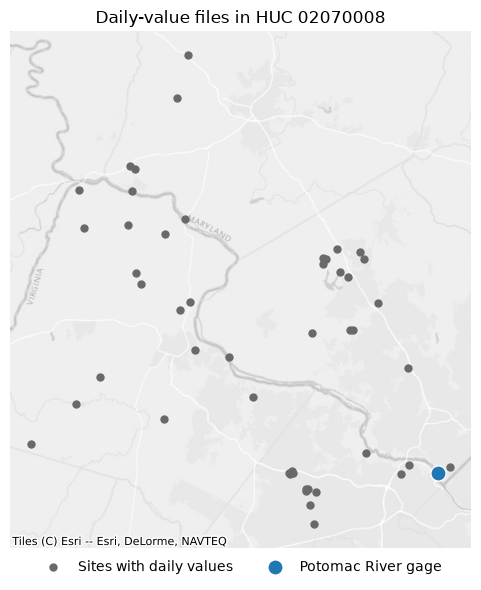

In [6]:
import contextily as ctx
import matplotlib.pyplot as plt
from xyzservices import providers

points = sites.to_crs(3857)
gage = points[points["id"] == SITE]
ax = points.plot(color="dimgray", markersize=25, figsize=(6, 6), label="Sites with daily values")
gage.plot(ax=ax, color="tab:blue", edgecolor="white", markersize=120, label="Potomac River gage")
ctx.add_basemap(ax, source=providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncols=2, frameon=False)
ax.set(title="Daily-value files in HUC 02070008")
ax.set_axis_off()
plt.tight_layout()

## Download and read the daily values

The asset files need no key. `Client.download()` fetches one to disk, creating its
folder. A download that carries a key counts against that key's hourly limit. The file
is Parquet, with each value stored as text.

In [7]:
import tempfile
from pathlib import Path

import polars as pl

from water_ogcapi import Client

item = stac.item("daily", SITE).body or {}
with Client() as client:
    path = Path(tempfile.mkdtemp()) / f"{SITE}.parquet"
    download = client.download(item["assets"]["data"]["href"], path)
print(f"{download.size:,} bytes")

daily = pl.read_parquet(path).with_columns(pl.col("value").cast(pl.Float64))
daily.group_by("parameter_code", "statistic_id").len().sort("len", descending=True)

848,638 bytes


parameter_code,statistic_id,len
str,str,u32
"""00060""","""00003""",35321
"""00010""","""00001""",24663
"""00010""","""00002""",24661
"""00010""","""00003""",24652
"""00095""","""00002""",12535
…,…,…
"""00300""","""00001""",4299
"""00300""","""00003""",4298
"""00400""","""00001""",4268


Parameter `00060` with statistic `00003` is the daily mean discharge, in ft³/s.

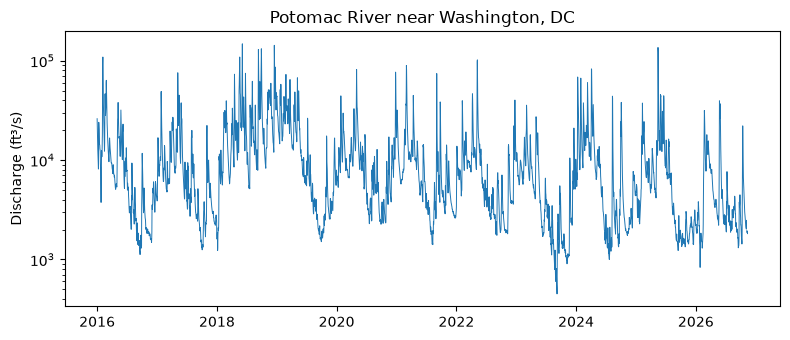

In [8]:
flow = daily.filter(
    pl.col("parameter_code") == "00060",
    pl.col("statistic_id") == "00003",
    pl.col("time").dt.year() >= 2016,
).sort("time")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(flow["time"], flow["value"], linewidth=0.7)
ax.set(yscale="log", ylabel="Discharge (ft³/s)", title="Potomac River near Washington, DC")
plt.tight_layout()

The two `continuous` files can be read the same way. If both hold a row for the same
`time_series_id` and `time`, keep the one with the latest `last_modified`.

In [9]:
stac.close()